# Tourism Monthly — global forecasting benchmark (N-BEATS included)

**Can N-BEATS, MLP, GRU, LSTM, TCN or a patch-based Transformer beat a strong global CatBoost baseline on 366 monthly time series?**

This is the **single, consolidated** Tourism Monthly benchmark notebook for the [time-series-forecasting](https://github.com/adidror005/time-series-forecasting) repository. It keeps the models from the previous `05_Tourism_Monthly_GLOBAL_NEW.ipynb` and adds an actual **generic N-BEATS residual backcast/forecast architecture**, implemented in PyTorch (not a renamed MLP, and not N-BEATSx).

**Dataset:** [Monash / Tourism Monthly (Zenodo 4656096)](https://zenodo.org/records/4656096). The ZIP is downloaded automatically. It contains 366 monthly time series. This is **not a new Chinese tourism dataset**.

**Experimental protocol, inherited from the previous notebook:**

- Forecast each series' **last 24 months**, using the previous **24 months as validation** and only earlier history for training.
- **18-month lookback** for all models. Global models share exactly the same training forecast origins, validation origins, and test origins. No training target may enter the validation or test periods.
- Normalize with scales computed only on the *training history*; forecasts are 24-month vectors expressed relative to the final history observation.
- Measure **macro-averaged seasonal MASE** (12-month seasonal-naive denominator estimated on training history). Also report MAE, sMAPE, per-series results, and per-horizon diagnostics.
- Models: seasonal naive, **N-BEATS**, MLP, GRU, LSTM, TCN, a compact patch Transformer, CatBoost raw-lag, and CatBoost with engineered features.
- **Feature caveat:** conventional N-BEATS is univariate and consumes only the 18 historical target values. The other neural models and CatBoost also receive *known* calendar features, and engineered CatBoost receives additional history-derived statistics. The split and targets are matched; feature sets are not identical.

A previous Hugging Face article and the Monash benchmark report model scores using **different pipelines**. Those scores are **not generated here** and should not be claimed as replicated. The actual benchmark results appear only when *you execute* all cells. There is no guarantee N-BEATS will win.

**Recommended environment:** Google Colab T4 GPU or local PyTorch with CUDA/MPS. CPU runs are possible but training the full suite (especially multi-output CatBoost) can take a while.


## 1. Setup and reproducibility

Run top-to-bottom with **Restart & Run All**. The notebook downloads the public data if it is not already cached under `benchmark_data/`. Only results from this run will appear: all previous notebook outputs have been cleared.

In [1]:
# Install if needed in a new Jupyter/Colab environment, then restart the kernel once:
# %pip install -q numpy pandas matplotlib torch catboost scipy
# This notebook implements N-BEATS in pure PyTorch: no neuralforecast dependency.
from pathlib import Path
import urllib.request, zipfile, math, json, time, os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display
from catboost import CatBoostRegressor

SEED = 42
LOOKBACK = 18
HORIZON = 24
VAL_MONTHS = 24
TEST_MONTHS = 24
MAX_EPOCHS = 50
PATIENCE = 8
BATCH_SIZE = 256
LEARNING_RATE = 0.001
CATBOOST_ITERATIONS = 400
CATBOOST_PATIENCE = 60
MAX_TRAIN_WINDOWS = 30000       # same deterministic subset of examples for all models
RUN_ENGINEERED_CATBOOST = True
# Generic N-BEATS architecture controls (all blocks use the SAME 18-month history)
NBEATS_STACKS = 3
NBEATS_BLOCKS_PER_STACK = 2
NBEATS_WIDTH = 256
NBEATS_HIDDEN_LAYERS = 4
NEURAL_MODELS = ['MLP','GRU','LSTM','TCN','Patch Transformer','N-BEATS']
DEVICE = torch.device('cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))
torch.set_num_threads(min(4, os.cpu_count() or 1))
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
print('Device:',DEVICE, '| torch',torch.__version__)

Device: mps | torch 2.12.0


## 2. Load Monash Tourism Monthly (366 series)

This retains the original `.tsf` parser and automatically downloads the official archive. For offline use, place `tourism_monthly_dataset.zip` inside `benchmark_data/` before running.

In [2]:
# Source: https://zenodo.org/records/4656096 (Monash Tourism Monthly 366 series)
DATA_URL='https://zenodo.org/api/records/4656096/files/tourism_monthly_dataset.zip/content'
cache_dir=Path('benchmark_data');cache_dir.mkdir(exist_ok=True)
archive_path=cache_dir/'tourism_monthly_dataset.zip'
if not archive_path.exists():
    print('Downloading',DATA_URL)
    try:urllib.request.urlretrieve(DATA_URL, archive_path)
    except Exception as e:raise RuntimeError('Download failed. Download tourism_monthly_dataset.zip from https://zenodo.org/records/4656096 and place it in benchmark_data/.') from e

def parse_tsf(contents):
    # Change 'utf-8-sig' to 'latin-1' to handle non-UTF-8 bytes in the file
    lines = contents.decode("latin-1").splitlines()
    attributes = []
    in_data = False
    series = []
    for line in lines:
      line = line.strip()
      if not line or line.startswith("#"):
        continue
      if line.startswith("@attribute"):
        attributes.append(line.split()[1])
        continue
      if line.lower() == "@data":
        in_data = True
        continue
      if line.startswith("@"):
        continue
      if not in_data:
        continue
      fields = line.split(":")
      if len(fields) != len(attributes) + 1:
        raise ValueError(
            f"Unexpected TSF row columns: expected {len(attributes) + 1}, got"
            f" {len(fields)}"
        )
      attrs = dict(zip(attributes, fields[:-1]))
      nums = np.array(
          [
              float(v) if v.strip() not in ("?", "NaN") else np.nan
              for v in fields[-1].split(",")
          ],
          dtype=np.float64,
      )
      if not np.all(np.isfinite(nums)):
        raise ValueError(
            "Unexpected missing value: review imputation before continuing"
        )
      if len(nums) < LOOKBACK + VAL_MONTHS + TEST_MONTHS:
        continue
      key = str(
          attrs.get("series_name", attrs.get("series_id", len(series)))
      )
      dt = str(attrs.get("start_timestamp", ""))
      try:
        start_month = int(pd.Period(dt[:7], freq="M").month)
      except Exception as ex:
        raise ValueError(f"Could not parse start_timestamp for {key}: {dt!r}") from ex
      series.append({"name": key, "values": nums, "start_month": start_month})
    return series
with zipfile.ZipFile(archive_path) as z:
    paths=[p for p in z.namelist() if p.lower().endswith('.tsf')]
    if not paths:raise ValueError(f'TSF file not found in archive: {z.namelist()}')
    series=parse_tsf(z.read(paths[0]))
if len(series)<3:raise ValueError(f'Only {len(series)} series loaded')
print('Number of series:',len(series),'min/median/max length:',
      min(len(s['values']) for s in series),int(np.median([len(s['values']) for s in series])),max(len(s['values']) for s in series))
print('First series',series[0]['name'], 'months',len(series[0]['values']))

Number of series: 366 min/median/max length: 91 330 333
First series T1 months 187


Series count: 366
History length summary:


,months
count,366.000000
mean,298.579235
std,55.651489
min,91.000000
25%,264.000000
50%,330.000000
75%,333.000000
max,333.000000


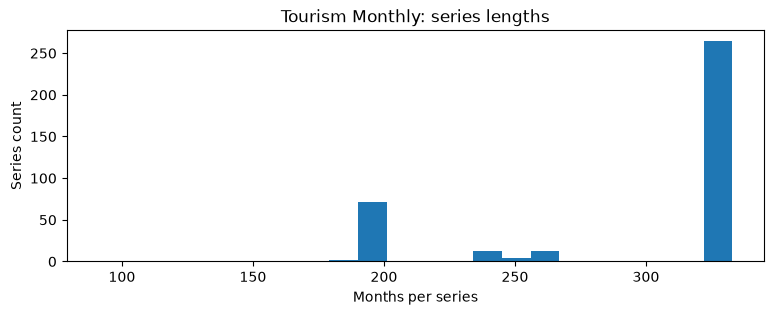

In [3]:
# Dataset sanity checks. No arbitrary data deletion or train/test reordering.
lengths = pd.Series([len(s['values']) for s in series])
assert len({s['name'] for s in series}) == len(series), 'Duplicate series labels; inspect dataset before continuing'
assert lengths.min() >= LOOKBACK + VAL_MONTHS + TEST_MONTHS
assert all(np.isfinite(s['values']).all() for s in series)
print('Series count:', len(series))
print('History length summary:')
display(lengths.describe().to_frame('months'))
fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(lengths, bins=22)
ax.set(xlabel='Months per series', ylabel='Series count', title='Tourism Monthly: series lengths')
plt.show()

## 3. Freeze leakage-safe train / validation / test windows

For each series, test is the last 24 observations, validation the 24 before that, and training targets must end **before validation starts**. `MAX_TRAIN_WINDOWS` is a deterministic optional cap on *training examples only*. Both test and validation always contain one full 24-month target per series.

In [4]:
# Forecast origins: train t+24 <= n-48; validation t=n-48; test t=n-24.
# No target for a training example is permitted to touch the two held-out blocks.
# Month-of-year is known in advance; future target data and future observations are not inputs.

def month_features(start_month,absolute_month):
    m=(start_month-1+np.asarray(absolute_month))%12
    return np.stack((np.sin(2*np.pi*m/12),np.cos(2*np.pi*m/12)),axis=-1).astype(np.float32)

for s in series:
    v=s['values'];n=len(v)
    cutoff=n-VAL_MONTHS-TEST_MONTHS
    s['scale']=max(float(np.mean(np.abs(v[:cutoff]))),1e-4)
    s['mase_scale']=max(float(np.mean(np.abs(v[12:cutoff]-v[:cutoff-12]))),1e-4)
    s['train_end']=cutoff

# X: history of relative scaled values + past seasonal phase. C: future known phase.
# Predictions and ground truth are both last-observation-relative and divided by series training scale.
def sample(s,t):
    v=s['values'];scale=s['scale'];anchor=float(v[t-1]);
    history=(v[t-LOOKBACK:t]-anchor)/scale
    month=month_features(s['start_month'],np.arange(t-LOOKBACK,t))
    x=np.column_stack((history,month)).astype(np.float32)
    c=month_features(s['start_month'],np.arange(t,t+HORIZON)).reshape(-1)
    y=((v[t:t+HORIZON]-anchor)/scale).astype(np.float32)
    return x,c,y,anchor

samples={p:[] for p in ('Train','Validation','Test')}
for sid,s in enumerate(series):
    n=len(s['values']);tr_end=s['train_end']
    for t in range(LOOKBACK,tr_end-HORIZON+1):samples['Train'].append((sid,t))
    samples['Validation'].append((sid,n-VAL_MONTHS-TEST_MONTHS))
    samples['Test'].append((sid,n-TEST_MONTHS))
assert len(samples['Train'])>0
if len(samples['Train'])>MAX_TRAIN_WINDOWS:
    idx=np.linspace(0,len(samples['Train'])-1,MAX_TRAIN_WINDOWS,dtype=int)
    samples['Train']=[samples['Train'][j] for j in idx]
for part,items in samples.items():
    for sid,t in items:
        n=len(series[sid]['values'])
        if part=='Train':assert t+HORIZON<=n-VAL_MONTHS-TEST_MONTHS
        if part=='Validation':assert t==n-VAL_MONTHS-TEST_MONTHS
        if part=='Test':assert t==n-TEST_MONTHS

def pack(part):
    xs=[];cs=[];ys=[];anchors=[];sids=[]
    for sid,t in samples[part]:
        x,c,y,a=sample(series[sid],t)
        xs.append(x);cs.append(c);ys.append(y);anchors.append(a);sids.append(sid)
    return np.stack(xs),np.stack(cs),np.stack(ys),np.asarray(anchors),np.asarray(sids)
packed={part:pack(part) for part in samples}
for part,(x,c,y,a,sid) in packed.items():
    print(part, 'examples:',len(y),'X',x.shape,'future_calendar',c.shape,'y',y.shape)
    assert np.all(np.isfinite(x)) and np.all(np.isfinite(c)) and np.all(np.isfinite(y))

# Future leakage test: no future change can alter sample inputs.
s=series[0];t=s['train_end'];x0,c0,_,_=sample(s,t)
alt=dict(s);alt['values']=s['values'].copy();alt['values'][t:]+=1e7
x1,c1,_,_=sample(alt,t)
assert np.array_equal(x0,x1) and np.array_equal(c0,c1)
print('Passed forecast-origin leakage assertions.')

Train examples: 30000 X (30000, 18, 3) future_calendar (30000, 48) y (30000, 24)
Validation examples: 366 X (366, 18, 3) future_calendar (366, 48) y (366, 24)
Test examples: 366 X (366, 18, 3) future_calendar (366, 48) y (366, 24)
Passed forecast-origin leakage assertions.


In [5]:
# Audit model-facing origins and shapes; these checks operate before model training.
assert len(samples['Validation']) == len(series) == len(samples['Test'])
assert len({sid for sid, _ in samples['Test']}) == len(series)
assert len({sid for sid, _ in samples['Validation']}) == len(series)
assert np.allclose(packed['Train'][0][:, -1, 0], 0.0, atol=1e-5)
assert all(s['mase_scale'] > 0 and s['scale'] > 0 for s in series)
for sid, s in enumerate(series):
    origins = [t for j, t in samples['Train'] if j == sid]
    if origins: assert max(t + HORIZON for t in origins) <= s['train_end']
print('Leakage audit passed | global train windows:', len(samples['Train']))
print('Validation and test forecast count:', len(samples['Validation']), len(samples['Test']))

Leakage audit passed | global train windows: 30000
Validation and test forecast count: 366 366


## 4. Forecasting architectures

The neural models retain the previous implementation. **N-BEATS has been added as a genuine generic N-BEATS**:

1. Each feed-forward block maps an input history residual into a **backcast** of length `LOOKBACK` and a **forecast** of length `HORIZON`.
2. The next block receives the history residual **minus the backcast**.
3. The final prediction is the **sum of block forecasts** across multiple stacks.

This is *not* merely a sequential MLP or an N-BEATSx model; no external regressors are passed to N-BEATS. A compact network is used here so the entire multi-model notebook remains practical. Increase `NBEATS_STACKS` or `NBEATS_WIDTH` to explore larger variants, but treat such changes as hyperparameter selection on validation—not test.

In [6]:
def metrics(pred,part):
    x,c,y,a,sids=packed[part]
    # pred is on the normalized relative-target scale.
    errors=[];smape=[];mae=[]
    for k,sid in enumerate(sids):
        s=series[int(sid)]
        pp=(np.asarray(pred[k])*s['scale'])+a[k]
        actual=(y[k]*s['scale'])+a[k]
        per_point_err=np.abs(pp-actual)
        errors.append(np.mean(per_point_err)/s['mase_scale'])
        smape.append(np.mean(2*per_point_err/np.maximum(np.abs(pp)+np.abs(actual),1e-6)))
        mae.append(np.mean(per_point_err))
    return dict(mase=float(np.mean(errors)),smape=float(np.mean(smape)*100),mae=float(np.mean(mae)))

class MLP(nn.Module):
    def __init__(self):
        super().__init__();self.net=nn.Sequential(nn.Linear(LOOKBACK*3+2*HORIZON,256),nn.ReLU(),nn.Dropout(.1),nn.Linear(256,128),nn.ReLU(),nn.Linear(128,HORIZON))
    def forward(self,x,c):return self.net(torch.cat([x.flatten(1),c],dim=1))
class RNN(nn.Module):
    def __init__(self,kind):
        super().__init__();self.rnn=(nn.GRU if kind=='GRU' else nn.LSTM)(3,64,batch_first=True);self.head=nn.Linear(64+2*HORIZON,HORIZON)
    def forward(self,x,c):return self.head(torch.cat([self.rnn(x)[0][:,-1,:],c],dim=1))
class ResidualTCN(nn.Module):
    def __init__(self):
        super().__init__();self.layers=nn.ModuleList([nn.Conv1d(3 if i==0 else 64,64,3,dilation=2**i) for i in range(4)]);self.head=nn.Linear(64+2*HORIZON,HORIZON)
    def forward(self,x,c):
        z=x.transpose(1,2)
        for i,layer in enumerate(self.layers):
            d=2**i;z=F.relu(layer(F.pad(z,(2*d,0))))
        return self.head(torch.cat([z[:,:,-1],c],dim=1))
class PatchTransformer(nn.Module):
    def __init__(self):
        super().__init__();self.patch=nn.Linear(6*3,64);self.pos=nn.Parameter(torch.zeros(1,5,64));
        enc=nn.TransformerEncoderLayer(d_model=64,nhead=4,dim_feedforward=128,dropout=.1,batch_first=True)
        self.encoder=nn.TransformerEncoder(enc,num_layers=2,enable_nested_tensor=False)
        self.head=nn.Sequential(nn.Linear(5*64+2*HORIZON,128),nn.ReLU(),nn.Linear(128,HORIZON))
    def forward(self,x,c):
        # 18-month history -> 5 overlapping six-month patches, stride 3.
        p=x.unfold(dimension=1,size=6,step=3).permute(0,1,3,2).reshape(x.size(0),5,18)
        z=self.encoder(self.patch(p)+self.pos).flatten(1)
        return self.head(torch.cat([z,c],dim=1))

class NBEATSBlock(nn.Module):
    """Generic N-BEATS block: deep basis coefficients -> backcast + forecast."""
    def __init__(self, input_size, horizon, width=256, hidden_layers=4):
        super().__init__()
        layers = []
        d = input_size
        for _ in range(hidden_layers):
            layers.extend([nn.Linear(d, width), nn.ReLU()])
            d = width
        self.layers = nn.Sequential(*layers)
        self.backcast = nn.Linear(d, input_size)
        self.forecast = nn.Linear(d, horizon)

    def forward(self, residual):
        z = self.layers(residual)
        return self.backcast(z), self.forecast(z)

class NBEATS(nn.Module):
    """Generic N-BEATS with doubly residual backcast/forecast connections.

    Genuine univariate architecture: input past normalized target history only;
    unlike N-BEATSx, it does not use external covariates or future calendar.
    """
    def __init__(self):
        super().__init__()
        self.blocks = nn.ModuleList([
            NBEATSBlock(LOOKBACK, HORIZON, NBEATS_WIDTH, NBEATS_HIDDEN_LAYERS)
            for _ in range(NBEATS_STACKS * NBEATS_BLOCKS_PER_STACK)
        ])

    def forward(self, x, c):
        # Shape: [batch, LOOKBACK]; last-observation-relative, train-only scale.
        residual = x[:, :, 0]
        forecast = torch.zeros((x.size(0), HORIZON), dtype=x.dtype, device=x.device)
        for block in self.blocks:
            backcast, block_forecast = block(residual)
            residual = residual - backcast
            forecast = forecast + block_forecast
        return forecast

FACTORIES={'N-BEATS':NBEATS,'MLP':MLP,'GRU':lambda:RNN('GRU'),'LSTM':lambda:RNN('LSTM'),'TCN':ResidualTCN,'Patch Transformer':PatchTransformer}

def loader(part,shuffle=False):
    x,c,y,*_=packed[part]
    return DataLoader(TensorDataset(torch.from_numpy(x),torch.from_numpy(c),torch.from_numpy(y)),batch_size=BATCH_SIZE,shuffle=shuffle)

@torch.no_grad()
def infer(model,part):
    model.eval();parts=[]
    for x,c,_ in loader(part):parts.append(model(x.to(DEVICE),c.to(DEVICE)).cpu().numpy())
    return np.concatenate(parts,axis=0)

def train_model(name):
    torch.manual_seed(SEED)
    model=FACTORIES[name]().to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=1e-4)
    best=float('inf');best_state=None;best_epoch=None;stale=0
    for epoch in range(1,MAX_EPOCHS+1):
        model.train()
        for x,c,y in loader('Train',shuffle=True):
            opt.zero_grad(set_to_none=True)
            loss=F.mse_loss(model(x.to(DEVICE),c.to(DEVICE)),y.to(DEVICE))
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.0);opt.step()
        pred=infer(model,'Validation');yv=packed['Validation'][2]
        val_mse=float(np.mean((pred-yv)**2))
        if val_mse<best-1e-6:
            best=val_mse;best_epoch=epoch;stale=0
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:
            stale+=1
            if stale>=PATIENCE:break
    model.load_state_dict(best_state)
    return model,best_epoch


In [7]:
# Architecture-level smoke check (no data fitting): correct shape and backprop.
_nbeats_check = NBEATS()
_x = torch.randn(3, LOOKBACK, 3)
_c = torch.randn(3, 2 * HORIZON)
_z = _nbeats_check(_x, _c)
assert _z.shape == (3, HORIZON) and torch.isfinite(_z).all()
_z.square().mean().backward()
# The final block's backcast head has no downstream forecast use, so its
# gradient can legitimately be None. All *existing* gradients must be finite.
_grads = [p.grad for p in _nbeats_check.parameters() if p.grad is not None]
assert _grads and all(torch.isfinite(g).all() for g in _grads)
print('N-BEATS output and gradient tests passed | trainable parameters:',
      sum(p.numel() for p in _nbeats_check.parameters()))
del _nbeats_check, _x, _c, _z

N-BEATS output and gradient tests passed | trainable parameters: 1278204


## 5. Fit the neural models and seasonal-naive control

Neural networks share the same optimizer, early-stopping rule, train origins, and validation MSE. This section can take several minutes or longer depending on hardware; the printout shows progress at the end of each model. **N-BEATS is included in the normal training loop.**

In [8]:
# Strong seasonal-naive comparator: repeat the same calendar months a year ago.
def seasonal_naive(part):
    out=[]
    for sid,t in samples[part]:
        s=series[sid];v=s['values'];a=v[t-1]
        seasonal=v[t-12:t] # known past 12 months
        forecast=np.tile(seasonal,int(math.ceil(HORIZON/12)))[:HORIZON]
        out.append((forecast-a)/s['scale'])
    return np.stack(out)

rows=[];predictions={};validation_predictions={}
for name in NEURAL_MODELS:
    start=time.perf_counter()
    model,ep=train_model(name)
    pred=infer(model,'Test');pv=infer(model,'Validation')
    predictions[name]=pred
    validation_predictions[name]=pv
    row={'model':name,'family':'Neural','best_epoch':ep,'train_seconds':round(time.perf_counter()-start,2),
         'val_mase':metrics(pv,'Validation')['mase'],**metrics(pred,'Test')}
    rows.append(row)
    print(f'{name:18s} test MASE={row["mase"]:.4f} val MASE={row["val_mase"]:.4f} epoch={ep}',flush=True)

naive_pred=seasonal_naive('Test');naive_val=seasonal_naive('Validation')
predictions['Seasonal naive']=naive_pred
validation_predictions['Seasonal naive']=naive_val
rows.append({'model':'Seasonal naive','family':'Naive','best_epoch':None,'train_seconds':0.0,
             'val_mase':metrics(naive_val,'Validation')['mase'],**metrics(naive_pred,'Test')})

MLP                test MASE=1.6752 val MASE=1.8220 epoch=4
GRU                test MASE=2.1149 val MASE=2.1902 epoch=19
LSTM               test MASE=2.0349 val MASE=2.0914 epoch=42
TCN                test MASE=1.7184 val MASE=1.9035 epoch=5
Patch Transformer  test MASE=1.7583 val MASE=1.8865 epoch=11
N-BEATS            test MASE=1.8561 val MASE=1.8628 epoch=2


## 6. CatBoost — raw history and engineered lag features

The global CatBoost regressors use direct **24-output** `MultiRMSE` models, not a weaker recursive one-step baseline. Their calendar information is known ahead of the forecast; all fitted model targets are restricted to the same training period as the neural models.

In [9]:
# The SAME history and known future calendar are given to raw-lag CatBoost.
def flat(part,engineered=False):
    x,c,*_=packed[part]
    a=np.concatenate([x.reshape(len(x),-1),c],axis=1)
    if engineered:
        v=x[:,:,0]
        extra=np.column_stack([
          v.mean(1),v.std(1),v.min(1),v.max(1),
          v[:,-3:].mean(1),v[:,-6:].mean(1),v[:,-12:].mean(1),
          v[:,-1]-v[:,-12],v[:,-1]-v[:,0],
          v[:,-6:].std(1),v[:,-12:].std(1),
          v[:,-12]-v[:,0]
        ])
        a=np.concatenate((a,extra),axis=1)
    return a.astype(np.float32)

for engineered in ([False,True] if RUN_ENGINEERED_CATBOOST else [False]):
    name='CatBoost (engineered)' if engineered else 'CatBoost (raw lags)'
    tic=time.perf_counter()
    model=CatBoostRegressor(iterations=CATBOOST_ITERATIONS,depth=6,learning_rate=.05,loss_function='MultiRMSE',
                            l2_leaf_reg=3,random_seed=SEED,task_type='CPU',thread_count=4,allow_writing_files=False)
    model.fit(flat('Train',engineered),packed['Train'][2],
              eval_set=(flat('Validation',engineered),packed['Validation'][2]),
              early_stopping_rounds=CATBOOST_PATIENCE,use_best_model=True,verbose=False)
    pred=model.predict(flat('Test',engineered));pv=model.predict(flat('Validation',engineered))
    predictions[name]=pred
    validation_predictions[name]=pv
    row={'model':name,'family':'Tree','best_epoch':model.tree_count_,'train_seconds':round(time.perf_counter()-tic,2),
         'val_mase':metrics(pv,'Validation')['mase'],**metrics(pred,'Test')}
    rows.append(row)
    print(f'{name:23s} test MASE={row["mase"]:.4f} val MASE={row["val_mase"]:.4f} trees={model.tree_count_}',flush=True)

CatBoost (raw lags)     test MASE=1.8742 val MASE=1.8983 trees=396
CatBoost (engineered)   test MASE=1.9464 val MASE=1.9398 trees=322


## 7. Main comparison — held-out test MASE

**Lower is better.** The model selected by validation is shown separately, so an attractive test ranking is never silently used as model-selection evidence.

,model,family,best_epoch,train_seconds,val_mase,mase,smape,mae
0,MLP,Neural,4.0,4.21,1.8220,1.6752,20.0539,1985.0278
1,TCN,Neural,5.0,5.07,1.9035,1.7184,20.1301,1953.3707
2,Patch Transformer,Neural,11.0,15.53,1.8865,1.7583,20.4661,1960.4046
3,Seasonal naive,Naive,NaN,0.00,1.9951,1.7805,21.6699,1980.2072
4,N-BEATS,Neural,2.0,11.72,1.8628,1.8561,21.5117,2338.6612
5,CatBoost (raw lags),Tree,396.0,34.64,1.8983,1.8742,20.8416,2166.0920
6,CatBoost (engineered),Tree,322.0,37.86,1.9398,1.9464,21.5404,2288.9007
7,LSTM,Neural,42.0,27.35,2.0914,2.0349,22.8597,2375.5032
8,GRU,Neural,19.0,23.28,2.1902,2.1149,23.3159,2593.1994


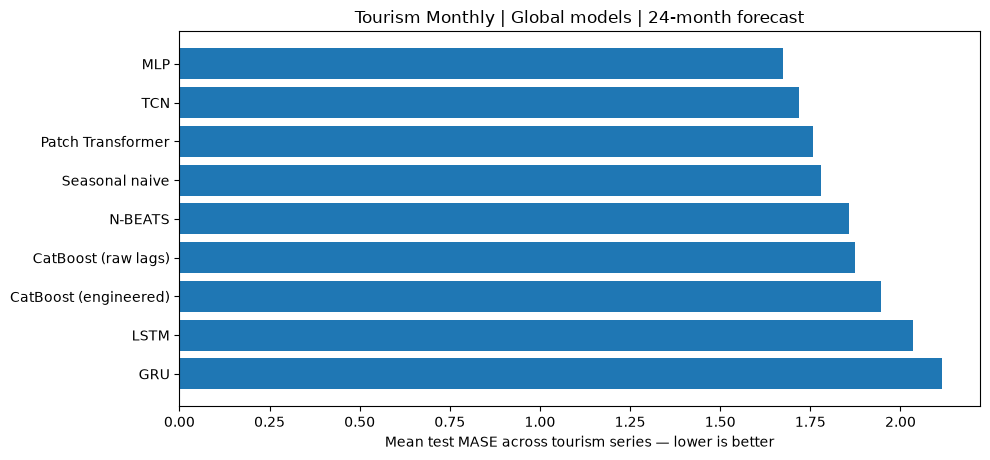

Validation-selected model: MLP | its held-out test MASE: 1.6752
Post-hoc test ranking should NOT be used to tune or select datasets.
Saved outputs: /Users/adidror/code/time-series-forecasting/Time_Series_Benchmark_Final/forecast_challenge_outputs/tourism_monthly


In [10]:
# Only executed results (never embedded claims copied from papers).
out=Path('forecast_challenge_outputs/tourism_monthly');out.mkdir(parents=True,exist_ok=True)
summary=pd.DataFrame(rows).sort_values('mase').reset_index(drop=True)
display(summary.round(4))
summary.to_csv(out/'comparison.csv',index=False)
fig,ax=plt.subplots(figsize=(10,4.7))
s=summary.iloc[::-1]
ax.barh(s.model,s.mase)
ax.set(xlabel='Mean test MASE across tourism series — lower is better',title='Tourism Monthly | Global models | 24-month forecast')
fig.tight_layout();fig.savefig(out/'mase_ranking.png',dpi=150);plt.show()
selected=summary.query('family!="Naive"').sort_values('val_mase').iloc[0]
print('Validation-selected model:',selected.model,'| its held-out test MASE:',round(selected.mase,4))
print('Post-hoc test ranking should NOT be used to tune or select datasets.')
np.savez_compressed(out/'predictions.npz',**{k.replace(' ','_').replace('(','').replace(')',''):v for k,v in predictions.items()})
config={'dataset':'tourism_monthly','source':DATA_URL,'num_series':len(series),'seed':SEED,
        'lookback':LOOKBACK,'horizon':HORIZON,'validation_block_months':VAL_MONTHS,
        'test_block_months':TEST_MONTHS,'max_epochs':MAX_EPOCHS,'patience':PATIENCE,
        'catboost_iterations':CATBOOST_ITERATIONS,'catboost_patience':CATBOOST_PATIENCE,
        'train_windows':len(samples['Train']),'neural_models':NEURAL_MODELS,
        'notes':'Separate global panel experiment, not identical to published Transformer/CatBoost setup or single-series suite.'}
(out/'run_info.json').write_text(json.dumps(config,indent=2),encoding='utf8')
print('Saved outputs:',out.resolve())

## How to interpret the results

- **Use the validation column to choose configurations; report the final test column only after the model choices are frozen.** The `selected` row above is validation-selected, not picked by whichever wins on test.
- **N-BEATS is the original generic architecture pattern** (feed-forward blocks, backcast residual subtraction, forecast residual addition), using our compact stack/block widths and training policy. It is not guaranteed to reproduce the Monash published N-BEATS score; an 18-month history and limited training budget may materially affect accuracy.
- CatBoost's calendar features and engineered features provide useful known information; note this difference when describing the contest.
- Model conclusions are specific to this dataset, preprocessing, hyperparameters, and split. If tuning based on test results, re-run with another independent test set before making claims.
- The cells below provide per-series metrics, paired comparisons, horizon error curves, example plots, and CSV/JSON exports for the article or GitHub README.


## 8. Per-series errors and model win counts

Aggregate MASE gives every series equal weight. We also save one row for every model/series pair. The win counts show whether a model wins broadly or only on a few series, which is essential when interpreting global forecasting models.

In [11]:
per_series_rows = []
for model_name, pred in predictions.items():
    assert pred.shape == (len(samples['Test']), HORIZON)
    for k, (sid, t) in enumerate(samples['Test']):
        s = series[sid]
        forecast = pred[k] * s['scale'] + packed['Test'][3][k]
        truth = s['values'][t:t + HORIZON]
        err = np.abs(forecast - truth)
        per_series_rows.append({
            'model': model_name, 'series_id': sid, 'series_name': s['name'],
            'n_months': len(s['values']),
            'MASE': float(err.mean() / s['mase_scale']),
            'MAE': float(err.mean()),
            'sMAPE_pct': float(np.mean(2 * err / np.maximum(np.abs(forecast) + np.abs(truth), 1e-6)) * 100),
        })
per_series = pd.DataFrame(per_series_rows)
assert per_series.groupby('model').size().eq(len(series)).all()
# Independent check that per-series and summary MASE agree.
for _, row in summary.iterrows():
    calculated = per_series.loc[per_series.model.eq(row.model), 'MASE'].mean()
    assert np.isclose(calculated, row.mase, rtol=2e-5, atol=1e-5), (row.model, calculated, row.mase)

winners = (per_series.sort_values(['series_id', 'MASE', 'model'])
           .groupby('series_id', as_index=False).first())
win_counts = (winners.groupby('model').size().rename('series_wins')
              .sort_values(ascending=False).to_frame())
print('Best test MASE per series (descriptive, post-hoc):')
display(win_counts)
print('Distribution of MASE by model:')
display(per_series.groupby('model').MASE.agg(['mean', 'median', 'std', 'min', 'max']).sort_values('mean').round(4))
per_series.to_csv(out / 'per_series_metrics.csv', index=False)
win_counts.to_csv(out / 'per_series_winner_counts.csv')

Best test MASE per series (descriptive, post-hoc):


,series_wins
model,
Seasonal naive,106
Patch Transformer,68
N-BEATS,52
MLP,45
TCN,31
CatBoost (raw lags),22
CatBoost (engineered),19
LSTM,13
GRU,10


Distribution of MASE by model:


,mean,median,std,min,max
model,,,,,
MLP,1.6752,1.4619,0.9122,0.4142,9.4033
TCN,1.7184,1.5202,0.9925,0.3987,10.3723
Patch Transformer,1.7583,1.5286,1.0858,0.4607,12.3761
Seasonal naive,1.7805,1.5262,1.0995,0.4113,10.2105
N-BEATS,1.8561,1.6692,0.9303,0.5255,10.1902
CatBoost (raw lags),1.8742,1.5770,1.2753,0.3589,13.1605
CatBoost (engineered),1.9464,1.6013,1.3274,0.3369,13.0878
LSTM,2.0349,1.7383,1.2092,0.4260,11.0110
GRU,2.1149,1.8282,1.2051,0.3259,11.9835


## 9. Does N-BEATS beat CatBoost *series by series*?

Use the matched 366 series rather than only the aggregate. A positive CatBoost-minus-N-BEATS MASE means N-BEATS was better on that series. We estimate an **exploratory paired bootstrap interval** by resampling series (not months or overlapping windows). This is *not* a formal universal superiority claim, and benchmark series may not be independent.

Comparator: CatBoost (engineered)
N-BEATS wins on 175/366 series (47.8%)
Average CatBoost minus N-BEATS MASE: +0.0903
Exploratory 95% paired-series bootstrap interval: [+0.0205, +0.1680]


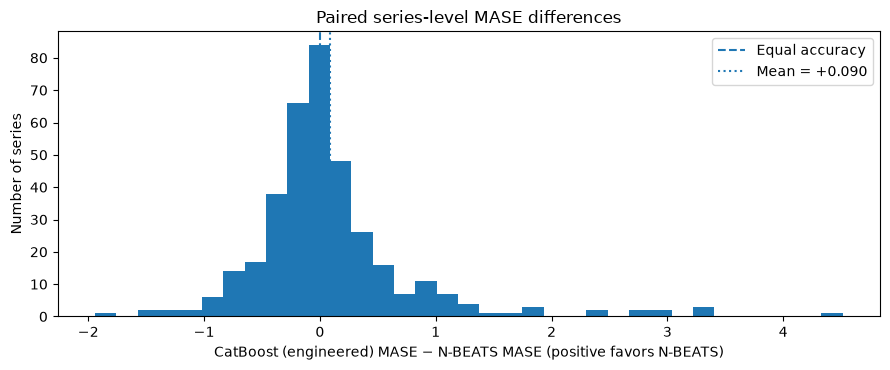

In [12]:
if 'N-BEATS' in predictions:
    comparison_tree = ('CatBoost (engineered)' if 'CatBoost (engineered)' in predictions
                       else 'CatBoost (raw lags)')
    pivot = per_series.pivot(index='series_id', columns='model', values='MASE')
    improvement = (pivot[comparison_tree] - pivot['N-BEATS']).to_numpy()
    win_rate = float(np.mean(improvement > 0))
    avg_gain = float(improvement.mean())
    rng = np.random.default_rng(SEED)
    boot = np.array([rng.choice(improvement, size=len(improvement), replace=True).mean()
                     for _ in range(2000)])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print('Comparator:', comparison_tree)
    print(f'N-BEATS wins on {np.sum(improvement > 0)}/{len(improvement)} series ({win_rate:.1%})')
    print(f'Average CatBoost minus N-BEATS MASE: {avg_gain:+.4f}')
    print(f'Exploratory 95% paired-series bootstrap interval: [{lo:+.4f}, {hi:+.4f}]')
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.hist(improvement, bins=35)
    ax.axvline(0, linestyle='--', label='Equal accuracy')
    ax.axvline(avg_gain, linestyle=':', label=f'Mean = {avg_gain:+.3f}')
    ax.set(xlabel=f'{comparison_tree} MASE − N-BEATS MASE (positive favors N-BEATS)',
           ylabel='Number of series', title='Paired series-level MASE differences')
    ax.legend()
    fig.tight_layout()
    fig.savefig(out / 'nbeats_vs_catboost_by_series.png', dpi=160)
    plt.show()
    paired_df = pd.DataFrame({'series_id': pivot.index,
                              'catboost_minus_nbeats_MASE': improvement})
    paired_df.to_csv(out / 'nbeats_vs_catboost_paired.csv', index=False)

## 10. Forecast errors by horizon (months 1–24)

A model might excel at 1–6 months yet fail at 18–24 months. Plot mean absolute error scaled by each series' **training-only seasonal denominator** at every horizon. The average of the 24 points reproduces the macro MASE.

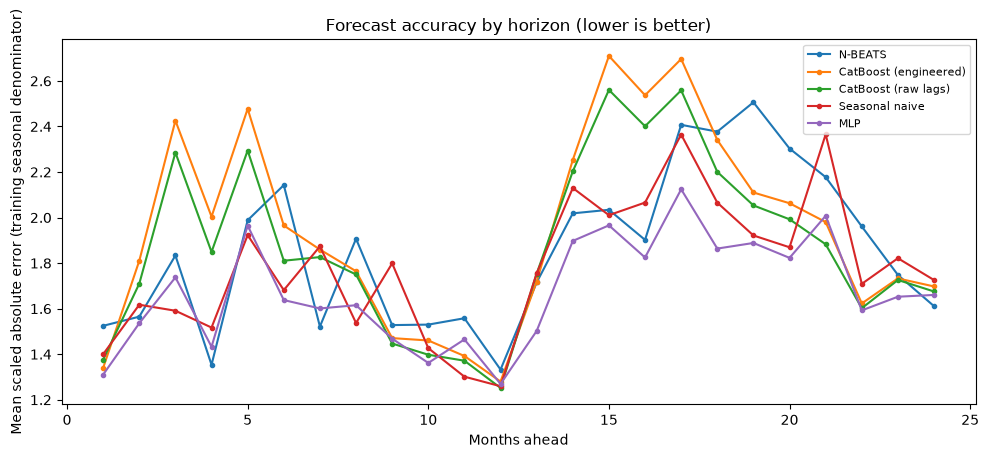

In [13]:
per_horizon_rows = []
for model_name, pred in predictions.items():
    scaled_error = np.empty((len(series), HORIZON), dtype=float)
    for k, (sid, t) in enumerate(samples['Test']):
        s = series[sid]
        forecast = pred[k] * s['scale'] + packed['Test'][3][k]
        scaled_error[k] = np.abs(forecast - s['values'][t:t + HORIZON]) / s['mase_scale']
    for h in range(HORIZON):
        per_horizon_rows.append({'model': model_name, 'horizon': h + 1,
                                 'mean_scaled_absolute_error': float(scaled_error[:, h].mean())})
per_horizon = pd.DataFrame(per_horizon_rows)
per_horizon.to_csv(out / 'horizon_error.csv', index=False)

focus = list(dict.fromkeys(['N-BEATS', 'CatBoost (engineered)',
                            'CatBoost (raw lags)', 'Seasonal naive', str(selected.model)]))
fig, ax = plt.subplots(figsize=(10, 4.6))
for name in focus:
    part = per_horizon[per_horizon.model.eq(name)]
    if len(part): ax.plot(part.horizon, part.mean_scaled_absolute_error, marker='.', label=name)
ax.set(xlabel='Months ahead', ylabel='Mean scaled absolute error (training seasonal denominator)',
       title='Forecast accuracy by horizon (lower is better)')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(out / 'error_by_horizon.png', dpi=160)
plt.show()

## 11. Illustrative forecasts from a series selected *without test outcomes*

To avoid cherry-picking, choose the **median-length series** based only on dataset metadata. The plot overlays N-BEATS, the two CatBoost variants, seasonal naive, and the validation-selected model if different. This is an illustration, not the overall benchmark evidence.

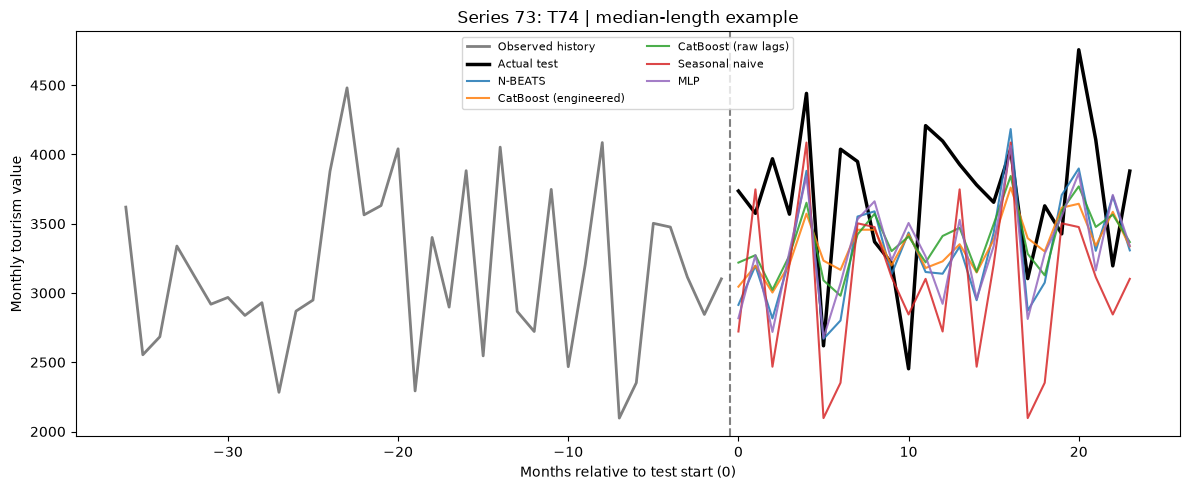

In [14]:
# Index chosen without looking at test errors or model ranks.
length_order = np.argsort(np.asarray([len(s['values']) for s in series]))
example_sid = int(length_order[len(length_order) // 2])
example_k = next(k for k, (sid, t) in enumerate(samples['Test']) if sid == example_sid)
s = series[example_sid]
t = samples['Test'][example_k][1]
lookback_months = min(36, t)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(np.arange(-lookback_months, 0), s['values'][t-lookback_months:t],
        color='gray', label='Observed history', linewidth=2)
ax.plot(np.arange(HORIZON), s['values'][t:t+HORIZON],
        color='black', label='Actual test', linewidth=2.5)
for name in focus:
    if name in predictions:
        p = predictions[name][example_k] * s['scale'] + packed['Test'][3][example_k]
        ax.plot(np.arange(HORIZON), p, label=name, alpha=0.85)
ax.axvline(-0.5, color='gray', linestyle='--')
ax.set(xlabel='Months relative to test start (0)', ylabel='Monthly tourism value',
       title=f'Series {example_sid}: {s["name"]} | median-length example')
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig(out / 'median_length_series_forecast.png', dpi=160)
plt.show()

## 12. Full long-form test predictions for reproducibility

The exported `test_predictions.csv` contains **every model, every series, and all 24 horizons**, with original-scale actual values, forecasts, absolute errors, and training-derived MASE scales. `target_month_of_year` is the true calendar month **if the dataset start timestamp is accurate**; numerical time indices are always present.

In [15]:
forecast_rows = []
for model_name, pred in predictions.items():
    for k, (sid, t) in enumerate(samples['Test']):
        s = series[sid]
        forecast = pred[k] * s['scale'] + packed['Test'][3][k]
        actual = s['values'][t:t + HORIZON]
        for h in range(HORIZON):
            forecast_rows.append({
                'model': model_name, 'series_id': sid, 'series_name': s['name'],
                'horizon': h + 1, 'target_index': t + h,
                'target_month_of_year': int((s['start_month'] - 1 + t + h) % 12 + 1),
                'actual': float(actual[h]), 'prediction': float(forecast[h]),
                'absolute_error': float(abs(forecast[h] - actual[h])),
                'train_mase_denominator': s['mase_scale'],
            })
forecast_table = pd.DataFrame(forecast_rows)
assert len(forecast_table) == len(predictions) * len(series) * HORIZON
assert np.isfinite(forecast_table[['actual', 'prediction', 'absolute_error']].to_numpy()).all()
forecast_table.to_csv(out / 'test_predictions.csv', index=False)
print('Saved', len(forecast_table), 'individual test prediction rows')
display(forecast_table.head(8))

Saved 79056 individual test prediction rows


,model,series_id,series_name,horizon,target_index,target_month_of_year,actual,prediction,absolute_error,train_mase_denominator
0,MLP,0,T1,1,163,8,6611.1150,6045.262053,565.852947,186.995092
1,MLP,0,T1,2,164,9,4150.2395,4127.449019,22.790481,186.995092
2,MLP,0,T1,3,165,10,2841.0000,3297.401289,456.401289,186.995092
3,MLP,0,T1,4,166,11,1813.4400,2432.163984,618.723984,186.995092
4,MLP,0,T1,5,167,12,2261.0800,1630.361250,630.718750,186.995092
5,MLP,0,T1,6,168,1,1873.6050,2054.956953,181.351953,186.995092
6,MLP,0,T1,7,169,2,1772.8400,1796.046309,23.206309,186.995092
7,MLP,0,T1,8,170,3,2049.5650,2394.203535,344.638535,186.995092


## 13. Export experiment configuration and validate CSV artifacts

Use `comparison.csv` for article tables. All data is saved under `forecast_challenge_outputs/tourism_monthly/`. Results **remain run-dependent**: CPU/GPU backend, package versions, and training randomness can change exact outcomes.

In [16]:
import platform
experiment_config = {
    'dataset': 'Monash Tourism Monthly',
    'dataset_record': 'https://zenodo.org/records/4656096',
    'series_count': len(series), 'seed': SEED,
    'lookback': LOOKBACK, 'horizon': HORIZON,
    'validation_months': VAL_MONTHS, 'test_months': TEST_MONTHS,
    'max_training_windows': MAX_TRAIN_WINDOWS,
    'actual_training_windows': len(samples['Train']),
    'epochs_max': MAX_EPOCHS, 'early_stopping_patience': PATIENCE,
    'nbeats_stacks': NBEATS_STACKS,
    'nbeats_blocks_per_stack': NBEATS_BLOCKS_PER_STACK,
    'nbeats_width': NBEATS_WIDTH,
    'nbeats_hidden_layers': NBEATS_HIDDEN_LAYERS,
    'nbeats_uses_calendar_covariates': False,
    'catboost_uses_known_calendar': True,
    'device': str(DEVICE), 'python': platform.python_version(),
    'torch': torch.__version__, 'numpy': np.__version__,
    'pandas': pd.__version__,
    'models_completed': list(predictions),
    'metric_definition': 'macro mean across series of 24-step MAE / train-only seasonal naive MAE (lag 12)',
    'test_used_for_model_selection': False,
}
(out / 'run_config.json').write_text(json.dumps(experiment_config, indent=2, default=str))
assert (out / 'comparison.csv').exists()
assert (out / 'per_series_metrics.csv').exists()
assert (out / 'test_predictions.csv').exists()
print('Artifacts in', out.resolve())
for artifact in sorted(out.iterdir()):
    if artifact.is_file(): print(f' {artifact.name:42s} {artifact.stat().st_size/1024:8.1f} KB')

Artifacts in /Users/adidror/code/time-series-forecasting/Time_Series_Benchmark_Final/forecast_challenge_outputs/tourism_monthly
 comparison.csv                                  1.0 KB
 error_by_horizon.png                          199.8 KB
 horizon_error.csv                               6.9 KB
 mase_ranking.png                               41.4 KB
 median_length_series_forecast.png             204.3 KB
 nbeats_vs_catboost_by_series.png               41.8 KB
 nbeats_vs_catboost_paired.csv                   8.5 KB
 per_series_metrics.csv                        253.0 KB
 per_series_winner_counts.csv                    0.1 KB
 predictions.npz                               353.6 KB
 run_config.json                                 1.0 KB
 run_info.json                                   0.6 KB
 test_predictions.csv                         6695.1 KB


## 14. Optional: compare the validation-selected model with N-BEATS

The validation-selected model is the most defensible **single headline model** to report without retrospectively choosing the best test model. A reported test winner (from the full ranking) is still useful descriptively, as long as you explicitly label it post-hoc. This cell just prints a clean summary for writing the article.

In [17]:
print('=== Headline summary for your README / Medium article ===')
print('Dataset: Monash Tourism Monthly; 366 series (or actual loaded count shown below).')
print(f'Loaded series: {len(series)} | Forecast horizon: {HORIZON} | Lookback: {LOOKBACK}')
print(f'Validation-selected model: {selected.model} | test MASE: {selected.mase:.4f}')
if 'N-BEATS' in summary.model.values:
    nbeats_score = float(summary.loc[summary.model.eq('N-BEATS'), 'mase'].iloc[0])
    print(f'N-BEATS held-out test MASE: {nbeats_score:.4f}')
    for cb_name in ['CatBoost (engineered)', 'CatBoost (raw lags)']:
        if cb_name in summary.model.values:
            cb_score = float(summary.loc[summary.model.eq(cb_name), 'mase'].iloc[0])
            relative = (cb_score - nbeats_score) / cb_score * 100
            print(f'N-BEATS vs {cb_name}: {relative:+.2f}% lower MASE (positive favors N-BEATS)')
print('Comparisons are from this notebook, NOT published Monash or Hugging Face scores.')

=== Headline summary for your README / Medium article ===
Dataset: Monash Tourism Monthly; 366 series (or actual loaded count shown below).
Loaded series: 366 | Forecast horizon: 24 | Lookback: 18
Validation-selected model: MLP | test MASE: 1.6752
N-BEATS held-out test MASE: 1.8561
N-BEATS vs CatBoost (engineered): +4.64% lower MASE (positive favors N-BEATS)
N-BEATS vs CatBoost (raw lags): +0.97% lower MASE (positive favors N-BEATS)
Comparisons are from this notebook, NOT published Monash or Hugging Face scores.


---

### Notes for publishing

- **Do not claim N-BEATS beats CatBoost until you actually run this notebook**. The test comparison is conditional on the executed results.
- Keep the exact split and training budget when comparing runs; consider reporting multiple random seeds and validation-driven tuning for a more robust study.
- `N-BEATS` here means **generic N-BEATS**, using learned backcast and forecast heads with doubly residual connections. It is a compact from-scratch implementation; it is **not** the Nixtla release and **not** N-BEATSx.
- These results are **not a reproduction of the published Tourism Monthly benchmark** because our model sizes, 18-month lookback, 24-month validation block, feature availability, and training budgets differ.
- Replace the repository file with **`05_Tourism_Monthly_GLOBAL_NEW.ipynb`**, run it fully, and commit both the executed notebook and the exported result CSVs/figures (if you intend to publish the numbers).